In [1]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn scikit-learn catboost



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# GLOBAL VISUALIZATION THEME
# ==============================

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="deep",
    font="sans-serif",
    font_scale=1.0
)

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    "axes.titlepad": 14
})



In [3]:
import pandas as pd

# Membaca dataset
df = pd.read_csv("UrbanCabFare.csv")

# Ukuran dataset
print("========================")
print("Ukuran dataset:", df.shape)
print("========================")
# Informasi struktur dataset
print("========================")
df.info()
print("========================")

# Pemeriksaan missing value
print("========================")
print("\nMissing Value:")
print(df.isnull().sum())
print("========================")
# Pemeriksaan data duplikat
print("========================")
print("\nJumlah data duplikat:")
print(df.duplicated().sum())
print("========================")

Ukuran dataset: (1000, 16)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               1000 non-null   str    
 1   Driver_Name           985 non-null    str    
 2   City                  1000 non-null   str    
 3   Ride_Date             1000 non-null   str    
 4   Hour_of_Day           1000 non-null   int64  
 5   Day_of_Week           1000 non-null   str    
 6   Distance_km           1000 non-null   float64
 7   Traffic_Level         1000 non-null   str    
 8   Type_of_vehicle       1000 non-null   str    
 9   No_of_active_drivers  1000 non-null   int64  
 10  Ride_Requests         1000 non-null   int64  
 11  Demand_Supply_Ratio   1000 non-null   float64
 12  Trip_Duration         1000 non-null   int64  
 13  Base_Fare             1000 non-null   float64
 14  Surge_Multiplier      1000 non-null   float64
 15  Final_

In [4]:
print(df)

             User_ID        Driver_Name       City   Ride_Date  Hour_of_Day  \
0    USER-21819-Bcbf    Patrick Sanchez       Pune  05-11-2025            0   
1    USER-79402-SBvr    Meredith Barnes     Mumbai  13-10-2025            2   
2    USER-40781-yfJs         Ian Cooper  Bengaluru  16-06-2026            6   
3    USER-41316-rDOx        Amber Perez     Mumbai  15-10-2025            0   
4    USER-76483-RuXX   Kimberly Sanchez    Chennai  06-09-2025           10   
..               ...                ...        ...         ...          ...   
995  USER-58476-dLtZ          Alex Webb     Mumbai  28-06-2026           10   
996  USER-72188-xAVz  Colleen Blanchard     Mumbai  17-01-2026           10   
997  USER-50666-jAEb      Tiffany Bates     Mumbai  17-12-2025           19   
998  USER-93663-spNZ   Katherine Mullen  Hyderabad  16-10-2025           23   
999  USER-02867-fYZS      Ashlee Miller  Hyderabad  11-04-2026            9   

    Day_of_Week  Distance_km Traffic_Level Type_of_

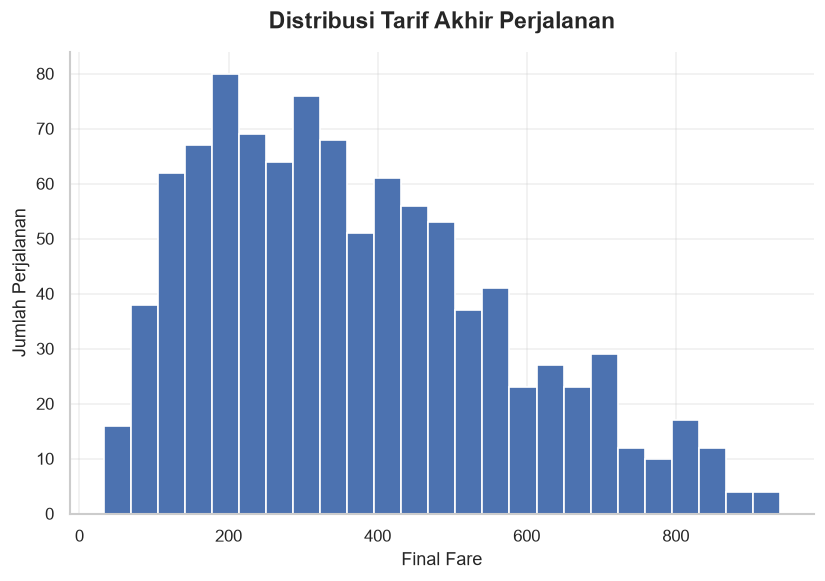

In [5]:
# ======== DISTRIBUSI TARIF AKHIR ==========

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["Final_Fare"], bins=25)

plt.title("Distribusi Tarif Akhir Perjalanan")
plt.xlabel("Final Fare")
plt.ylabel("Jumlah Perjalanan")

plt.show()

City
Delhi        412.941257
Bengaluru    393.863631
Mumbai       362.644268
Chennai      352.870294
Pune         352.824330
Hyderabad    348.835548
Name: Final_Fare, dtype: float64


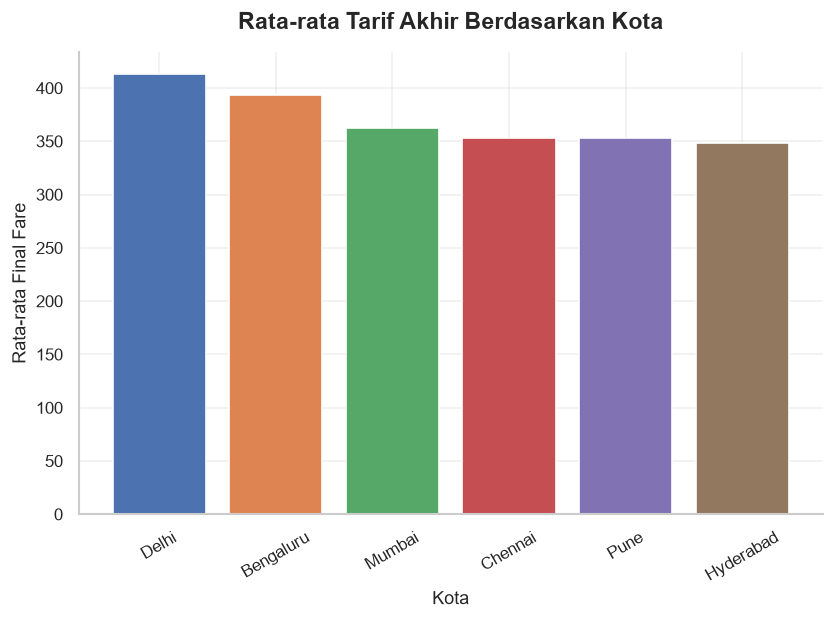

In [6]:
# ================= RATA RATA TARIF AKHIR BERDASARKAN KOTA =====================

city_mean = (
    df.groupby("City")["Final_Fare"]
    .mean()
    .sort_values(ascending=False)
)

print(city_mean)

plt.figure(figsize=(8, 5))

# colors = [
#     "#4E79A7", 
#     "#59A14F", 
#     "#9C755F", 
#     "#B07AA1", 
#     "#F28E2B",  
#     "#79706E"   
# ]

colors = sns.color_palette(
    "deep",
    # n_colors=len(validation_baseline)
)


plt.bar(city_mean.index, city_mean.values, color=colors)

plt.title("Rata-rata Tarif Akhir Berdasarkan Kota")
plt.xlabel("Kota")
plt.ylabel("Rata-rata Final Fare")
plt.xticks(rotation=30)

plt.show()

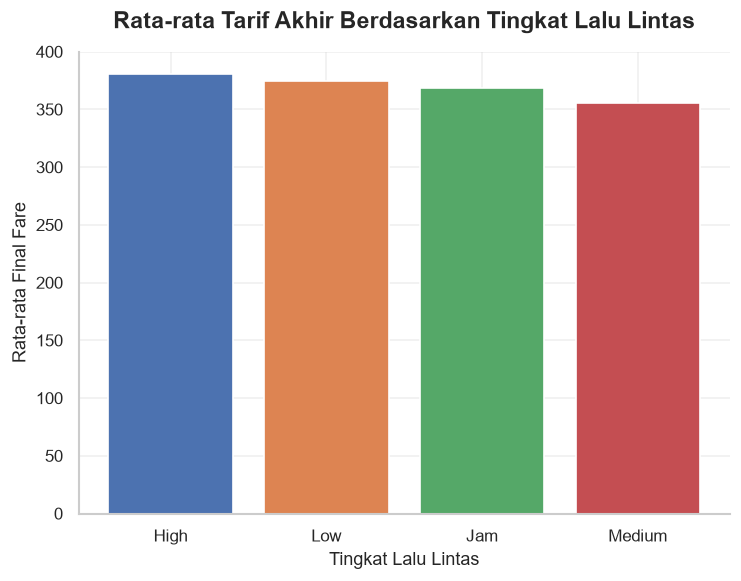

In [7]:
# ============ Rata-rata Tarif Akhir Berdasarkan Tingkat Lalu Lintas ===========

traffic_mean = (
    df.groupby("Traffic_Level")["Final_Fare"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))

# colors = ["#ffcc40", "#5840f5", "#1f9900", "#a62434"]

colors = sns.color_palette(
    "deep",
    # n_colors=len(validation_baseline)
)


plt.bar(traffic_mean.index, traffic_mean.values, color=colors)

plt.title("Rata-rata Tarif Akhir Berdasarkan Tingkat Lalu Lintas")
plt.xlabel("Tingkat Lalu Lintas")
plt.ylabel("Rata-rata Final Fare")

plt.show()

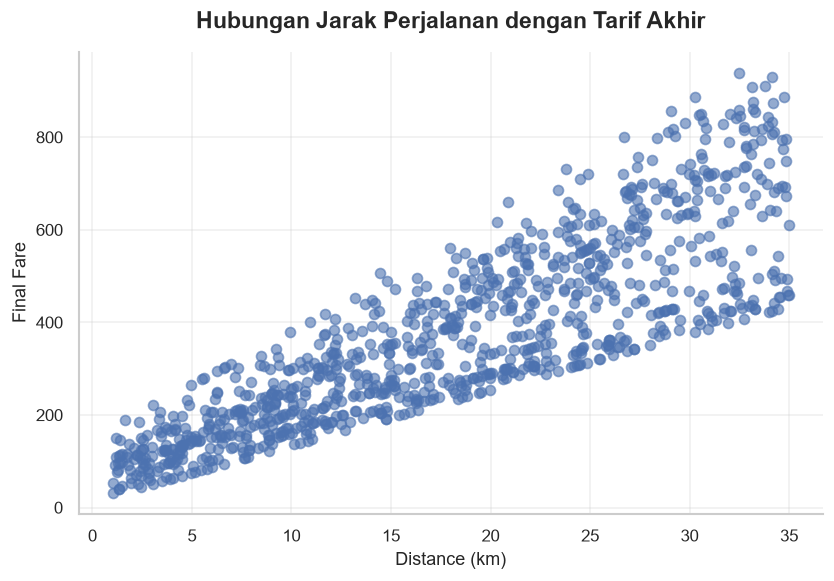

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Distance_km"],
    df["Final_Fare"],
    alpha=0.6
)

plt.title("Hubungan Jarak Perjalanan dengan Tarif Akhir")
plt.xlabel("Distance (km)")
plt.ylabel("Final Fare")

plt.show()

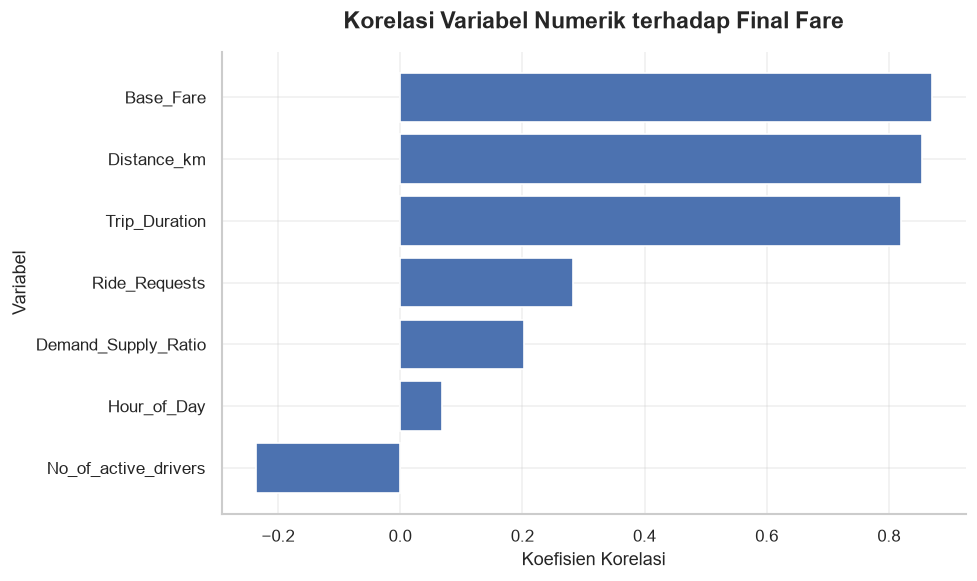

In [9]:
numeric_cols = df.select_dtypes(
    include="number"
).columns

correlation = (
    df[numeric_cols]
    .corr()["Final_Fare"]
    .drop(["Final_Fare", "Surge_Multiplier"])
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 5))

plt.barh(
    correlation.index,
    correlation.values
)

plt.title("Korelasi Variabel Numerik terhadap Final Fare")
plt.xlabel("Koefisien Korelasi")
plt.ylabel("Variabel")

plt.show()

=============== PREPROCESSING DATA ==================

In [10]:
# Cek missing value
missing_values = df.isnull().sum()

print("Missing value:")
print(missing_values[missing_values > 0])

Missing value:
Driver_Name    15
dtype: int64


In [11]:
# ========== HAPUS DATA YANG TIDAK DIPERLUKAN ============

df_model = df.drop(
    columns=[
        "User_ID",
        "Driver_Name",
        "Ride_Date",
        "Surge_Multiplier"
    ]
)
print("Kolom setelah penghapusan:")
print(df_model.columns)

print("\nUkuran dataset:")
print(df_model.shape)

Kolom setelah penghapusan:
Index(['City', 'Hour_of_Day', 'Day_of_Week', 'Distance_km', 'Traffic_Level',
       'Type_of_vehicle', 'No_of_active_drivers', 'Ride_Requests',
       'Demand_Supply_Ratio', 'Trip_Duration', 'Base_Fare', 'Final_Fare'],
      dtype='str')

Ukuran dataset:
(1000, 12)


In [12]:
# =============== ENCODING =============

categorical_cols = [
    "City",
    "Day_of_Week",
    "Traffic_Level",
    "Type_of_vehicle"
]

df_model = pd.get_dummies(
    df_model,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

print(df_model.head())

print("\nJumlah kolom:")
print(df_model.shape[1])

print(df_model.dtypes)

   Hour_of_Day  Distance_km  No_of_active_drivers  Ride_Requests  \
0            0        26.21                    36             67   
1            2        21.08                     9             17   
2            6        25.34                    94            149   
3            0        26.80                    25            188   
4           10         4.48                    53             34   

   Demand_Supply_Ratio  Trip_Duration  Base_Fare  Final_Fare  City_Bengaluru  \
0                 1.86             60     354.52      460.88               0   
1                 1.89             50     282.96      367.85               0   
2                 1.59             75     344.08      447.30               1   
3                 7.52             76     351.60      562.56               0   
4                 0.64             18     133.76      133.76               0   

   City_Chennai  ...  Day_of_Week_Wednesday  Traffic_Level_High  \
0             0  ...                      0

In [13]:
X = df_model.drop(columns=["Final_Fare"])
y = df_model["Final_Fare"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

Jumlah fitur: 29
Jumlah target: 1000


In [14]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=["Final_Fare"])
y = df_model["Final_Fare"]

# 70% training, 30% sementara
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training :", X_train.shape)
print("Validation:", X_val.shape)
print("Testing  :", X_test.shape)

Training : (700, 29)
Validation: (150, 29)
Testing  : (150, 29)


In [15]:
# Kolom target dan kolom yang tidak digunakan
target = "Final_Fare"

drop_cols = [
    "User_ID",
    "Driver_Name",
    "Ride_Date",
    "Surge_Multiplier"
]

df_catboost = df.drop(
    columns=drop_cols,
    errors="ignore"
).copy()

# Pisahkan fitur dan target
X_cat = df_catboost.drop(columns=[target]).copy()
y_cat = df_catboost[target].copy()

# Identifikasi kolom kategorikal
cat_features = X_cat.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Pastikan nilai kategorikal tidak berisi missing value
for col in cat_features:
    X_cat[col] = X_cat[col].fillna("Unknown").astype(str)

print("Kolom kategorikal:", cat_features)
print("Jumlah fitur:", X_cat.shape[1])

X_cat_train = X_cat.loc[X_train.index]
X_cat_val = X_cat.loc[X_val.index]
X_cat_test = X_cat.loc[X_test.index]

y_cat_train = y_cat.loc[X_train.index]
y_cat_val = y_cat.loc[X_val.index]
y_cat_test = y_cat.loc[X_test.index]



Kolom kategorikal: ['City', 'Day_of_Week', 'Traffic_Level', 'Type_of_vehicle']
Jumlah fitur: 11


BAB 3 MODELING

In [16]:
!{sys.executable} -m pip install xgboost scikit-learn pandas numpy matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Inisialisasi model baseline
models = {
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    ),
    "CatBoost": CatBoostRegressor(
        random_seed=42,
        verbose=0
    )
}

baseline_results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    for split_name, X_data, y_data in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:
        predictions = model.predict(X_data)

        baseline_results.append({
            "Model": name,
            "Dataset": split_name,
            "MAE": mean_absolute_error(
                y_data, predictions
            ),
            "RMSE": np.sqrt(
                mean_squared_error(y_data, predictions)
            ),
            "R2": r2_score(y_data, predictions)
        })

baseline_df = pd.DataFrame(baseline_results)



In [18]:
# =====================================
# CATBOOST NATIVE BASELINE
# =====================================

catboost_native_baseline = CatBoostRegressor(
    random_seed=42,
    verbose=0
)

# Training
catboost_native_baseline.fit(
    X_cat_train,
    y_cat_train,
    cat_features=cat_features
)

# Evaluasi Training dan Validation
baseline_native_results = []

for split_name, X_data, y_data in [
    ("Training", X_cat_train, y_cat_train),
    ("Validation", X_cat_val, y_cat_val)
]:
    predictions = catboost_native_baseline.predict(X_data)

    baseline_native_results.append({
        "Model": "CatBoost Native Baseline",
        "Dataset": split_name,
        "MAE": mean_absolute_error(y_data, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_data, predictions)
        ),
        "R2": r2_score(y_data, predictions)
    })

baseline_native_df = pd.DataFrame(baseline_native_results)


In [19]:
# Menggabungkan seluruh hasil evaluasi baseline
baseline_all = pd.concat(
    [baseline_df, baseline_native_df],
    ignore_index=True
)

# Mengubah nama model agar lebih ringkas
baseline_all["Model"] = baseline_all["Model"].replace({
    "CatBoost": "CatBoost One-Hot",
    "CatBoost Native Baseline": "CatBoost Native"
})

print(baseline_all.round(4).to_string(index=False))

           Model    Dataset     MAE    RMSE     R2
   Decision Tree   Training  0.0000  0.0000 1.0000
   Decision Tree Validation 26.4418 41.8987 0.9499
   Random Forest   Training  9.1755 14.0739 0.9951
   Random Forest Validation 24.2254 37.1985 0.9605
         XGBoost   Training  3.6664  5.2458 0.9993
         XGBoost Validation 25.4907 37.8462 0.9591
CatBoost One-Hot   Training  6.2265  8.2190 0.9983
CatBoost One-Hot Validation 23.8970 33.9657 0.9671
 CatBoost Native   Training 12.9825 18.2009 0.9918
 CatBoost Native Validation 22.4965 32.3946 0.9700


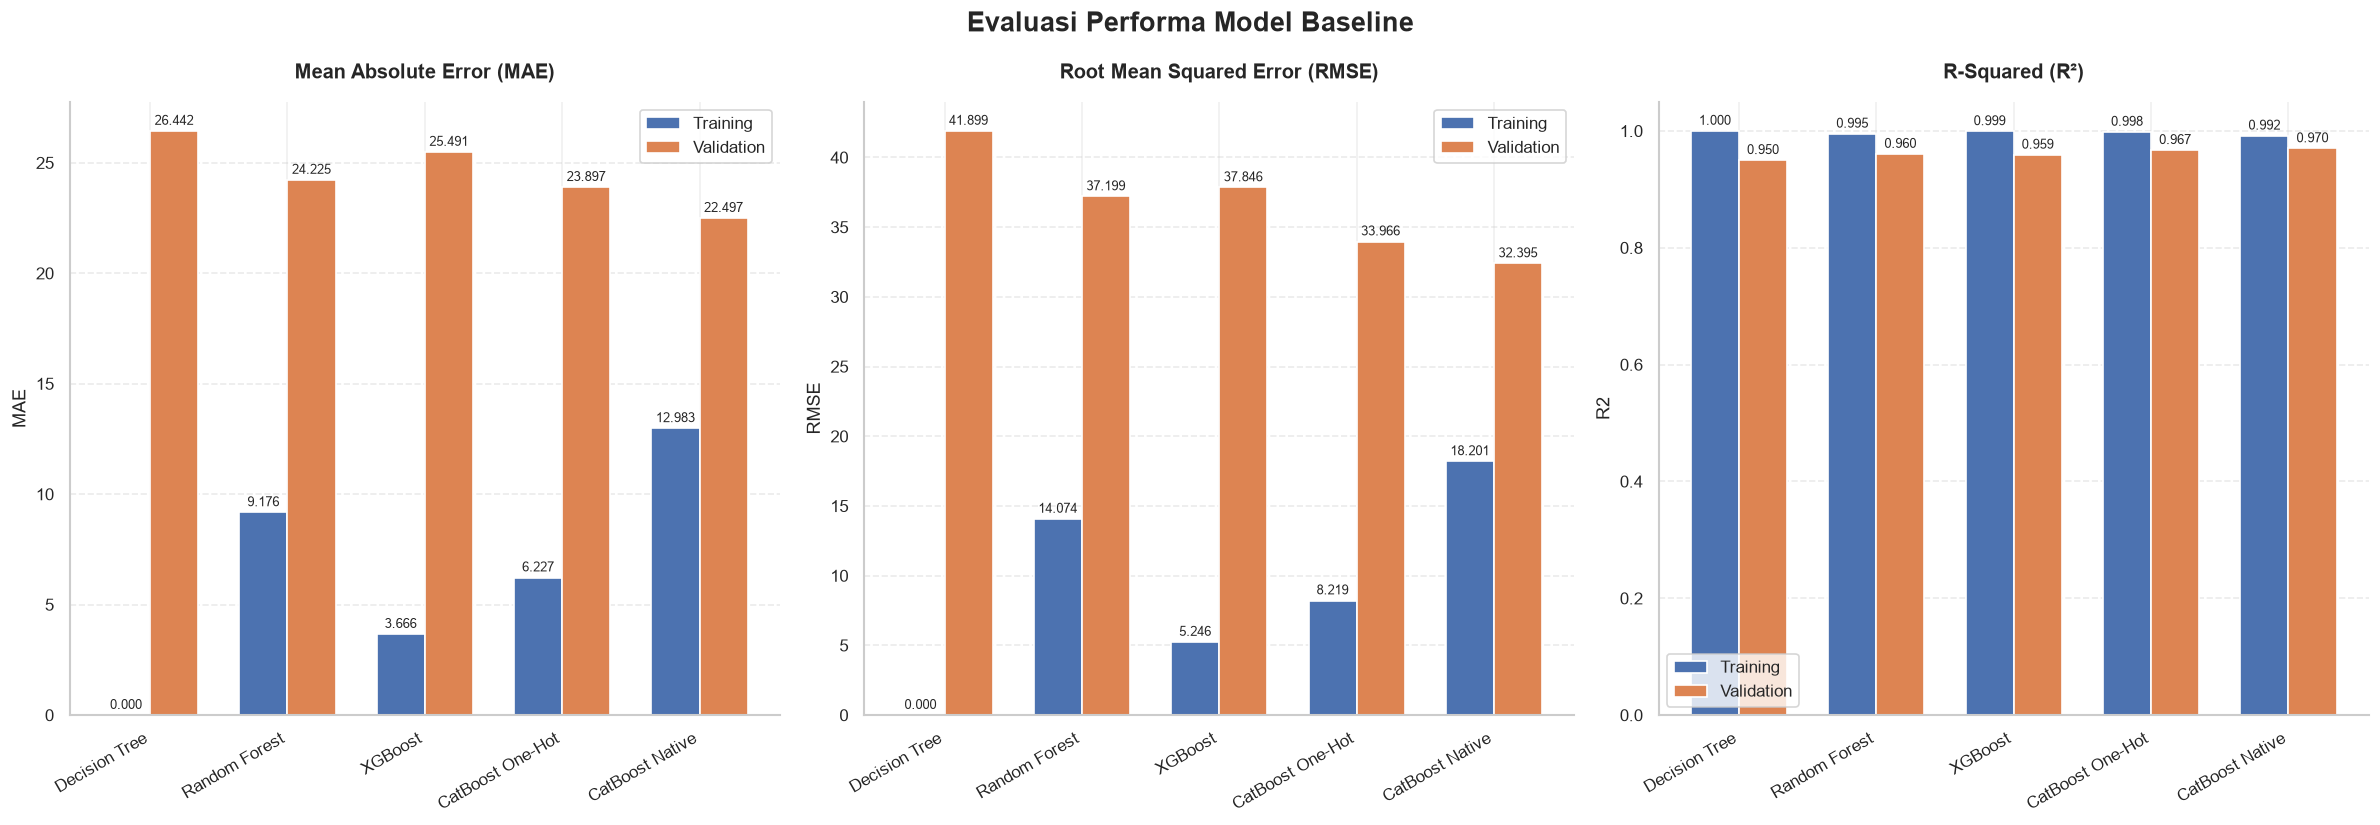

In [20]:
# Menggabungkan hasil baseline One-Hot dan Native
baseline_all = pd.concat(
    [baseline_df, baseline_native_df],
    ignore_index=True
)

# Menyesuaikan nama model
baseline_all["Model"] = baseline_all["Model"].replace({
    "CatBoost": "CatBoost One-Hot",
    "CatBoost Native Baseline": "CatBoost Native"
})

# Urutan model
model_order = [
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "CatBoost One-Hot",
    "CatBoost Native"
]

metrics = ["MAE", "RMSE", "R2"]

titles = [
    "Mean Absolute Error (MAE)",
    "Root Mean Squared Error (RMSE)",
    "R-Squared (R²)"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

x = np.arange(len(model_order))
width = 0.35

for ax, metric, title in zip(axes, metrics, titles):

    training_values = []
    validation_values = []

    for model in model_order:

        train_value = baseline_all[
            (baseline_all["Model"] == model) &
            (baseline_all["Dataset"] == "Training")
        ][metric].values[0]

        val_value = baseline_all[
            (baseline_all["Model"] == model) &
            (baseline_all["Dataset"] == "Validation")
        ][metric].values[0]

        training_values.append(train_value)
        validation_values.append(val_value)

    bars1 = ax.bar(
        x - width/2,
        training_values,
        width,
        label="Training"
    )

    bars2 = ax.bar(
        x + width/2,
        validation_values,
        width,
        label="Validation"
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=30, ha="right")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    ax.bar_label(bars1, fmt="%.3f", fontsize=8, padding=2)
    ax.bar_label(bars2, fmt="%.3f", fontsize=8, padding=2)

plt.suptitle(
    "Evaluasi Performa Model Baseline",
    fontsize=16,
    fontweight="bold"
)



plt.tight_layout()
plt.show()

In [21]:


from sklearn.model_selection import RandomizedSearchCV


# 1. Rentang hyperparameter Decision Tree
param_dt = {
    "max_depth": [3, 5, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10]
}

# 2. Rentang hyperparameter Random Forest
param_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.7, 1.0]
}

# 3. Rentang hyperparameter XGBoost
param_xgb = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5, 7],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0]
}

param_catboost = {
    "iterations": [100, 200, 300, 500],
    "depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.05, 0.1],
    "l2_leaf_reg": [3, 5, 7, 9]
}

# Model dan ruang pencarian
search_spaces = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        param_dt
    ),
    "Random Forest": (
        RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        param_rf
    ),
    "XGBoost": (
        XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1
        ),
        param_xgb
    ),
    "CatBoost": (
        CatBoostRegressor(
            loss_function="RMSE",
            random_seed=42,
            verbose=0,
            thread_count=1
        ),
        param_catboost
    )
}

tuned_models = {}
tuning_results = []

# 4. Proses pencarian parameter terbaik
for name, (estimator, param_dist) in search_spaces.items():

    print(f"\nMelakukan tuning: {name}")

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=20,
        scoring="neg_mean_absolute_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    # Simpan model dengan parameter terbaik
    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV MAE": -search.best_score_
    })

# 5. Tampilkan hasil tuning
tuning_df = pd.DataFrame(tuning_results)

print("\n=== HASIL HYPERPARAMETER TUNING ===")
print(tuning_df.to_string(index=False))



Melakukan tuning: Decision Tree

Melakukan tuning: Random Forest

Melakukan tuning: XGBoost

Melakukan tuning: CatBoost

=== HASIL HYPERPARAMETER TUNING ===
        Model                                                                                          Best Parameters    CV MAE
Decision Tree                                       {'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': None} 31.846674
Random Forest                       {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 15} 26.819624
      XGBoost {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.85} 26.877524
     CatBoost                                 {'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 300, 'depth': 6} 27.345085


In [22]:

# Rentang hyperparameter CatBoost
param_catboost = {
    "iterations": [100, 200, 300, 500],
    "depth": [4, 6, 8, 10],
    "learning_rate": [0.01, 0.05, 0.1],
    "l2_leaf_reg": [3, 5, 7, 9]
}

# Model CatBoost native
catboost_model = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=0,
    thread_count=1
)

# Randomized Search dengan 3-fold CV
catboost_search = RandomizedSearchCV(
    estimator=catboost_model,
    param_distributions=param_catboost,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    refit=True
)

print("Memulai tuning CatBoost native...")

catboost_search.fit(
    X_cat_train,
    y_cat_train,
    cat_features=cat_features
)

# Simpan model terbaik
catboost_native_tuned = catboost_search.best_estimator_

print("\n=== HASIL TUNING CATBOOST NATIVE ===")
print("Best parameters:", catboost_search.best_params_)
print("Best CV MAE:", round(-catboost_search.best_score_, 4))



Memulai tuning CatBoost native...

=== HASIL TUNING CATBOOST NATIVE ===
Best parameters: {'learning_rate': 0.05, 'l2_leaf_reg': 5, 'iterations': 300, 'depth': 6}
Best CV MAE: 27.8326


In [23]:
tuned_native_results = []

for split_name, X_data, y_data in [
    ("Training", X_cat_train, y_cat_train),
    ("Validation", X_cat_val, y_cat_val)
]:
    predictions = catboost_native_tuned.predict(X_data)

    tuned_native_results.append({
        "Model": "CatBoost Native Tuned",
        "Dataset": split_name,
        "MAE": mean_absolute_error(y_data, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_data, predictions)),
        "R2": r2_score(y_data, predictions)
    })

tuned_native_df = pd.DataFrame(tuned_native_results)


In [24]:
tuned_validation_results = []

for name, model in tuned_models.items():

    for split_name, X_data, y_data in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val)
    ]:
        predictions = model.predict(X_data)

        tuned_validation_results.append({
            "Model": name,
            "Dataset": split_name,
            "MAE": mean_absolute_error(y_data, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_data, predictions)
            ),
            "R2": r2_score(y_data, predictions)
        })

tuned_df = pd.DataFrame(tuned_validation_results)


In [25]:
# Menggabungkan hasil evaluasi seluruh model setelah tuning
tuned_all = pd.concat(
    [tuned_df, tuned_native_df],
    ignore_index=True
)

# Menyamakan nama model agar lebih rapi
tuned_all["Model"] = tuned_all["Model"].replace({
    "CatBoost": "CatBoost One-Hot",
    "CatBoost Native Tuned": "CatBoost Native"
})

# Mengurutkan hasil berdasarkan model dan dataset
model_order = [
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "CatBoost One-Hot",
    "CatBoost Native"
]

tuned_all["Model"] = pd.Categorical(
    tuned_all["Model"],
    categories=model_order,
    ordered=True
)

tuned_all = tuned_all.sort_values(
    ["Model", "Dataset"],
    ascending=[True, True]
)

# Menampilkan hasil
print("=== HASIL EVALUASI SELURUH MODEL SETELAH TUNING ===")
print(tuned_all.round(4).to_string(index=False))

=== HASIL EVALUASI SELURUH MODEL SETELAH TUNING ===
           Model    Dataset     MAE    RMSE     R2
   Decision Tree   Training 15.9952 25.3588 0.9841
   Decision Tree Validation 26.1326 40.9393 0.9521
   Random Forest   Training 10.6065 16.5734 0.9932
   Random Forest Validation 23.9098 37.1244 0.9606
         XGBoost   Training 16.5705 23.3383 0.9865
         XGBoost Validation 23.7848 34.2608 0.9665
CatBoost One-Hot   Training 15.0018 20.3602 0.9897
CatBoost One-Hot Validation 24.3697 33.9683 0.9671
 CatBoost Native   Training 19.6886 27.5838 0.9811
 CatBoost Native Validation 22.1453 31.9957 0.9708


In [26]:
catboost_comparison = pd.DataFrame({
    "Tahap": ["Before Tuning", "After Tuning"],
    "MAE": [22.4965, 22.1453],
    "RMSE": [32.3946, 31.9957],
    "R2": [0.9700, 0.9708]
})

print(catboost_comparison.round(4).to_string(index=False))

        Tahap     MAE    RMSE     R2
Before Tuning 22.4965 32.3946 0.9700
 After Tuning 22.1453 31.9957 0.9708


=== PERBANDINGAN MAE VALIDATION ===
                 Before Tuning  After Tuning
Model                                       
CatBoost               23.8970       24.3697
CatBoost Native        22.4965       22.1453
Decision Tree          26.4418       26.1326
Random Forest          24.2254       23.9098
XGBoost                25.4907       23.7848


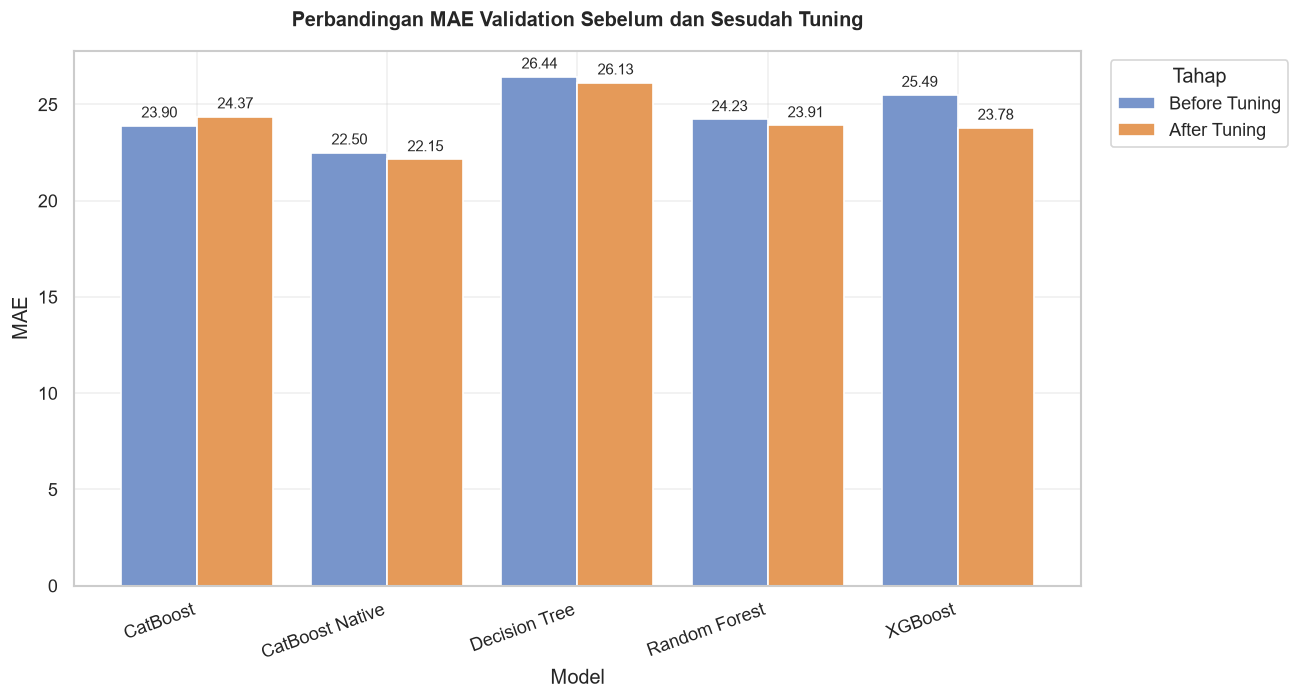

In [27]:
# 1. Ambil MAE validation dari model baseline
baseline_val = (
    baseline_df[baseline_df["Dataset"] == "Validation"]
    [["Model", "MAE"]]
    .copy()
    .rename(columns={"MAE": "Before Tuning"})
)

# 2. Ambil MAE validation dari model setelah tuning
tuned_val = (
    tuned_df[tuned_df["Dataset"] == "Validation"]
    [["Model", "MAE"]]
    .copy()
    .rename(columns={"MAE": "After Tuning"})
)


# 4. Tambahkan CatBoost Native dengan nama yang sama
native_baseline = pd.DataFrame({
    "Model": ["CatBoost Native"],
    "Before Tuning": [22.4965]
})

native_tuned = pd.DataFrame({
    "Model": ["CatBoost Native"],
    "After Tuning": [22.1453]
})

baseline_val = pd.concat(
    [
        baseline_val,
        native_baseline
    ],
    ignore_index=True
)

tuned_val = pd.concat(
    [
        tuned_val,
        native_tuned
    ],
    ignore_index=True
)

# 5. Gabungkan berdasarkan nama model
comparison = baseline_val.merge(
    tuned_val,
    on="Model",
    how="outer"
)

comparison = comparison.set_index("Model")

print("=== PERBANDINGAN MAE VALIDATION ===")
print(comparison.round(4).to_string())

# 6. Visualisasi
sns.set_theme(style="whitegrid")

ax = comparison.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#7895CB", "#E59A59"],
    width=0.8
)

ax.set_title(
    "Perbandingan MAE Validation Sebelum dan Sesudah Tuning",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Model")
ax.set_ylabel("MAE")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

ax.legend(
    title="Tahap",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

=== PERBANDINGAN RMSE VALIDATION ===
                 Before Tuning  After Tuning
Model                                       
CatBoost               33.9657       33.9683
CatBoost Native        32.3946       31.9957
Decision Tree          41.8987       40.9393
Random Forest          37.1985       37.1244
XGBoost                37.8462       34.2608


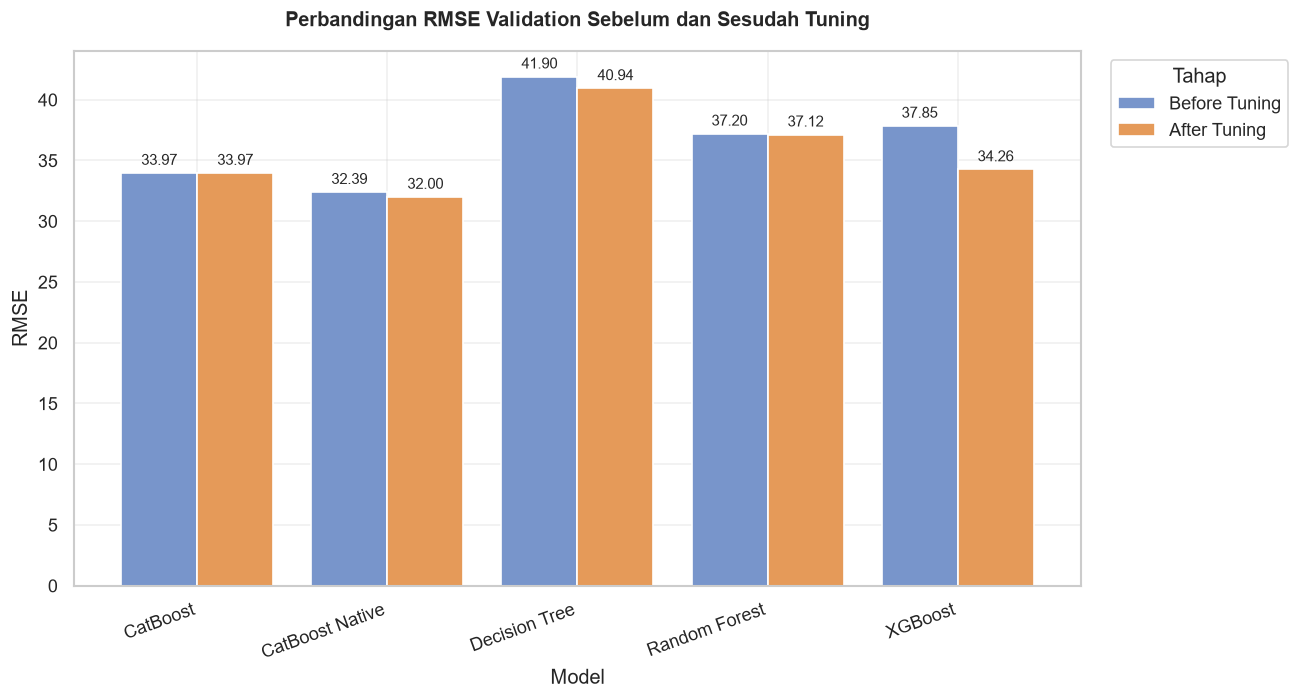

In [28]:
# Ambil RMSE validation baseline
baseline_rmse = (
    baseline_df[baseline_df["Dataset"] == "Validation"]
    [["Model", "RMSE"]]
    .copy()
    .rename(columns={"RMSE": "Before Tuning"})
)

# Ambil RMSE validation setelah tuning
tuned_rmse = (
    tuned_df[tuned_df["Dataset"] == "Validation"]
    [["Model", "RMSE"]]
    .copy()
    .rename(columns={"RMSE": "After Tuning"})
)


# Tambahkan CatBoost Native
native_baseline_rmse = pd.DataFrame({
    "Model": ["CatBoost Native"],
    "Before Tuning": [32.3946]
})

native_tuned_rmse = pd.DataFrame({
    "Model": ["CatBoost Native"],
    "After Tuning": [31.9957]
})

baseline_rmse = pd.concat(
    [baseline_rmse, native_baseline_rmse],
    ignore_index=True
)

tuned_rmse = pd.concat(
    [tuned_rmse, native_tuned_rmse],
    ignore_index=True
)

# Gabungkan hasil
comparison_rmse = baseline_rmse.merge(
    tuned_rmse,
    on="Model",
    how="outer"
).set_index("Model")

print("=== PERBANDINGAN RMSE VALIDATION ===")
print(comparison_rmse.round(4).to_string())

# Visualisasi
sns.set_theme(style="whitegrid")

ax = comparison_rmse.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#7895CB", "#E59A59"],
    width=0.8
)

ax.set_title(
    "Perbandingan RMSE Validation Sebelum dan Sesudah Tuning",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Model")
ax.set_ylabel("RMSE")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

ax.legend(
    title="Tahap",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

=== PERBANDINGAN R² VALIDATION ===
                 Before Tuning  After Tuning
Model                                       
CatBoost                0.9671        0.9671
CatBoost Native         0.9700        0.9708
Decision Tree           0.9499        0.9521
Random Forest           0.9605        0.9606
XGBoost                 0.9591        0.9665


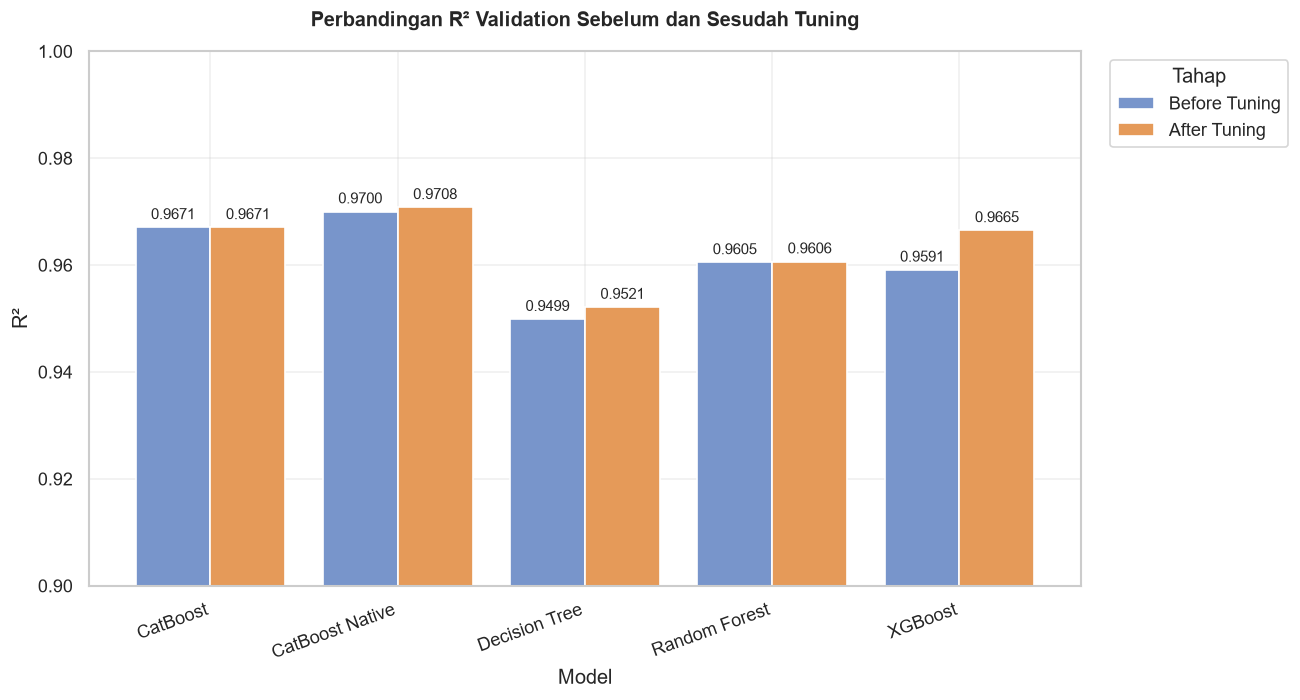

In [29]:
# Ambil R² validation baseline
baseline_r2 = (
    baseline_df[baseline_df["Dataset"] == "Validation"]
    [["Model", "R2"]]
    .copy()
    .rename(columns={"R2": "Before Tuning"})
)

# Ambil R² validation setelah tuning
tuned_r2 = (
    tuned_df[tuned_df["Dataset"] == "Validation"]
    [["Model", "R2"]]
    .copy()
    .rename(columns={"R2": "After Tuning"})
)

# Tambahkan CatBoost Native
native_baseline_r2 = pd.DataFrame({
    "Model": ["CatBoost Native"],
    "Before Tuning": [0.9700]
})

native_tuned_r2 = pd.DataFrame({
    "Model": ["CatBoost Native"],
    "After Tuning": [0.9708]
})

baseline_r2 = pd.concat(
    [baseline_r2, native_baseline_r2],
    ignore_index=True
)

tuned_r2 = pd.concat(
    [tuned_r2, native_tuned_r2],
    ignore_index=True
)

# Gabungkan hasil
comparison_r2 = baseline_r2.merge(
    tuned_r2,
    on="Model",
    how="outer"
).set_index("Model")

print("=== PERBANDINGAN R² VALIDATION ===")
print(comparison_r2.round(4).to_string())

# Visualisasi
ax = comparison_r2.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#7895CB", "#E59A59"],
    width=0.8
)

ax.set_title(
    "Perbandingan R² Validation Sebelum dan Sesudah Tuning",
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Model")
ax.set_ylabel("R²")

# Rentang sumbu dibuat dekat dengan nilai R² agar perbedaannya terlihat
ax.set_ylim(0.90, 1.00)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3, fontsize=9)

ax.legend(
    title="Tahap",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

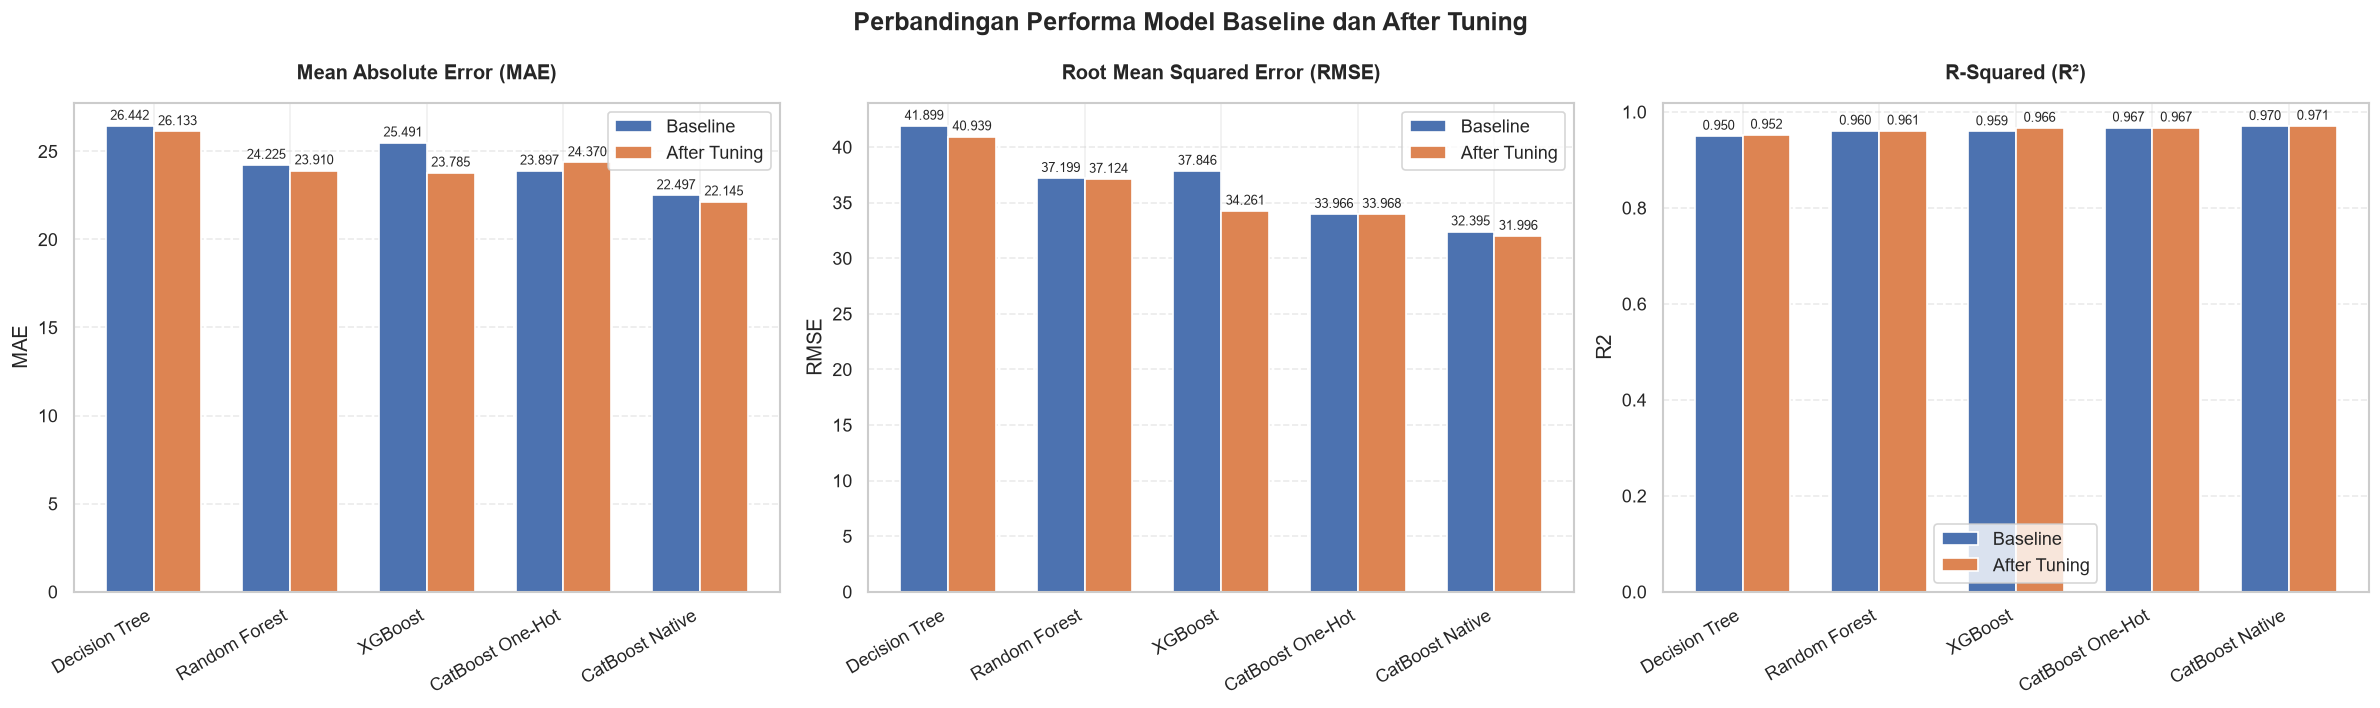

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Menambahkan label kondisi model
baseline_all["Kondisi"] = "Baseline"
tuned_all["Kondisi"] = "After Tuning"

# Menggabungkan baseline dan tuned
comparison_df = pd.concat(
    [baseline_all, tuned_all],
    ignore_index=True
)

# Mengambil data validation saja
validation_df = comparison_df[
    comparison_df["Dataset"] == "Validation"
].copy()

# Urutan model
model_order = [
    "Decision Tree",
    "Random Forest",
    "XGBoost",
    "CatBoost One-Hot",
    "CatBoost Native"
]

metrics = ["MAE", "RMSE", "R2"]
titles = [
    "Mean Absolute Error (MAE)",
    "Root Mean Squared Error (RMSE)",
    "R-Squared (R²)"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

x = np.arange(len(model_order))
width = 0.35

for ax, metric, title in zip(axes, metrics, titles):

    baseline_values = []
    tuned_values = []

    for model in model_order:
        baseline_value = validation_df[
            (validation_df["Model"] == model) &
            (validation_df["Kondisi"] == "Baseline")
        ][metric].values[0]

        tuned_value = validation_df[
            (validation_df["Model"] == model) &
            (validation_df["Kondisi"] == "After Tuning")
        ][metric].values[0]

        baseline_values.append(baseline_value)
        tuned_values.append(tuned_value)

    bars1 = ax.bar(
        x - width/2,
        baseline_values,
        width,
        label="Baseline"
    )

    bars2 = ax.bar(
        x + width/2,
        tuned_values,
        width,
        label="After Tuning"
    )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(
        model_order,
        rotation=30,
        ha="right"
    )

    ax.set_ylabel(metric)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.legend()

    ax.bar_label(bars1, fmt="%.3f", padding=2, fontsize=8)
    ax.bar_label(bars2, fmt="%.3f", padding=2, fontsize=8)

plt.suptitle(
    "Perbandingan Performa Model Baseline dan After Tuning",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

TESTING EVALUASI

In [31]:
# Periksa apakah observasi test set sama
print(X_test.index.equals(X_cat_test.index))

# Periksa apakah target test set sama
print(y_test.index.equals(y_cat_test.index))

True
True


In [32]:
# Model final yang akan dievaluasi menggunakan data testing

final_models = {
    "Decision Tree": tuned_models["Decision Tree"],
    "Random Forest": tuned_models["Random Forest"],
    "XGBoost": tuned_models["XGBoost"],
    "CatBoost One-Hot": models["CatBoost"],
    "CatBoost Native": catboost_native_tuned
}

In [34]:
# Menampung hasil evaluasi testing
testing_results = []

# Evaluasi model dengan One-Hot Encoding
for model_name, model in final_models.items():

    # CatBoost Native menggunakan dataset berbeda
    if model_name == "CatBoost Native":
        X_eval = X_cat_test
        y_eval = y_cat_test

    else:
        X_eval = X_test
        y_eval = y_test

    # Prediksi data testing
    y_pred = model.predict(X_eval)

    # Menghitung metrik evaluasi
    mae = mean_absolute_error(y_eval, y_pred)
    rmse = np.sqrt(mean_squared_error(y_eval, y_pred))
    r2 = r2_score(y_eval, y_pred)

    # Menyimpan hasil
    testing_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Membuat DataFrame hasil evaluasi
testing_df = pd.DataFrame(testing_results)

# Mengurutkan berdasarkan MAE terkecil
testing_df = testing_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("Hasil Evaluasi Model pada Data Testing")
print(testing_df.round(4).to_string(index=False))

Hasil Evaluasi Model pada Data Testing
           Model     MAE    RMSE     R2
CatBoost One-Hot 26.4571 38.9057 0.9624
   Random Forest 26.7273 40.1763 0.9599
 CatBoost Native 27.7217 39.6370 0.9609
         XGBoost 28.2525 41.0397 0.9581
   Decision Tree 32.3692 47.0344 0.9450


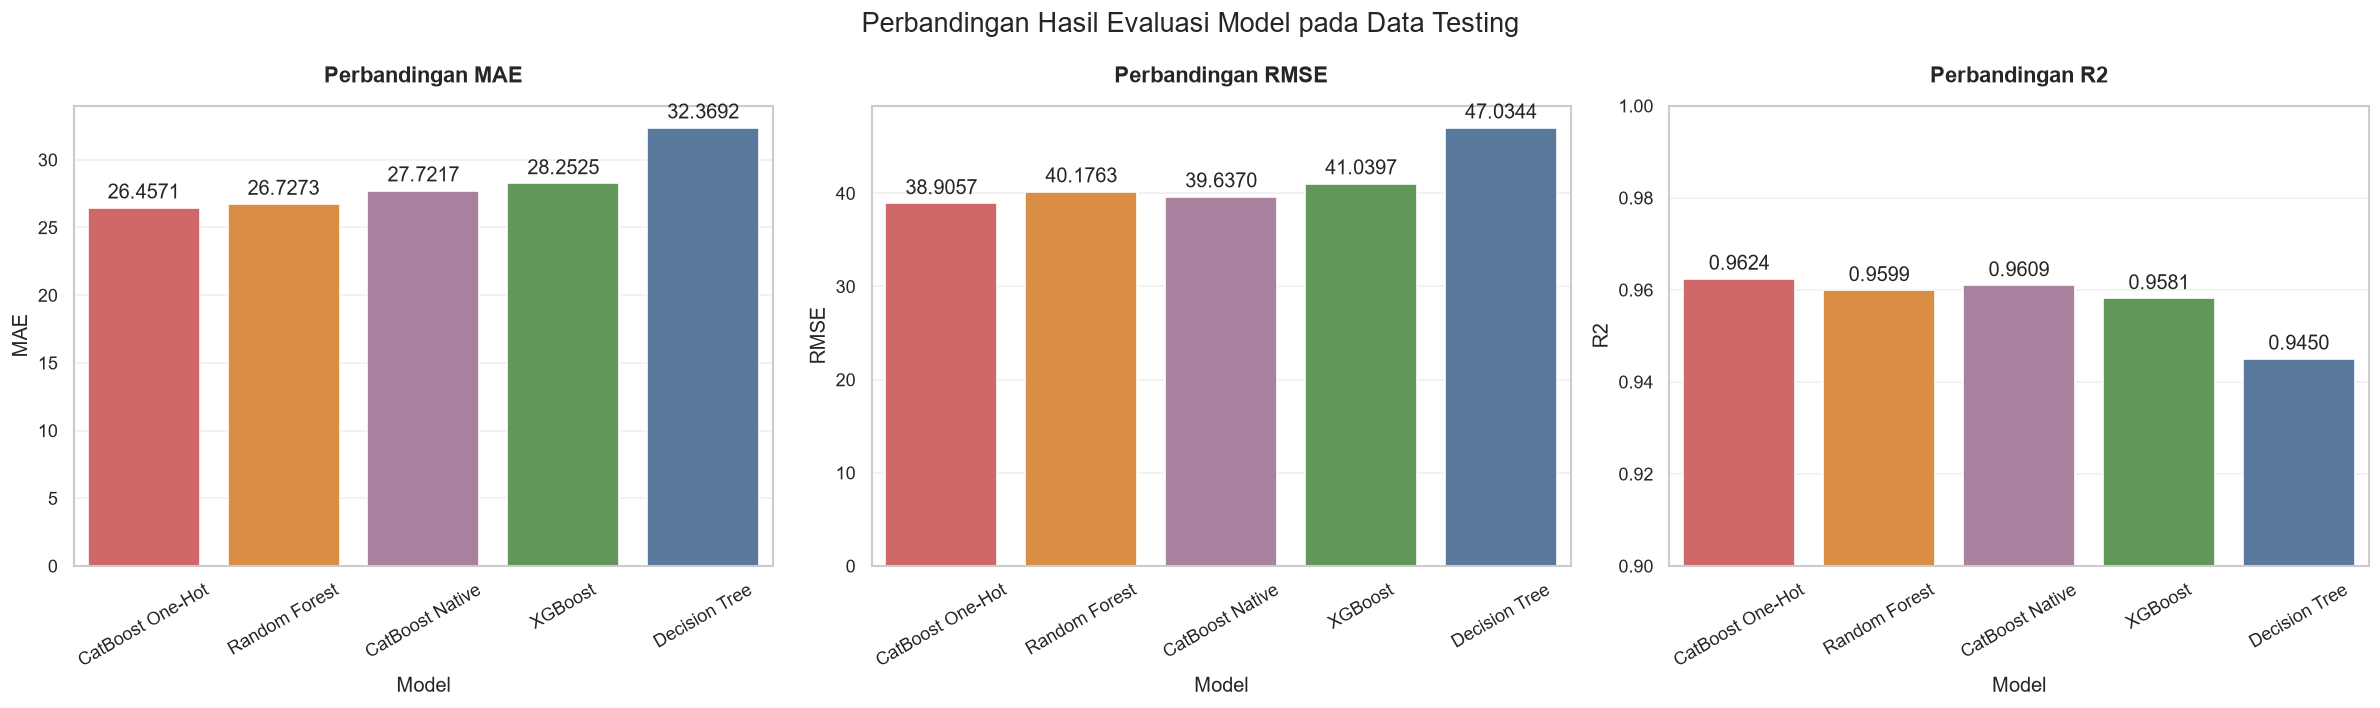

In [43]:
metrics = ["MAE", "RMSE", "R2"]

# Warna berbeda untuk setiap model
model_colors = {
    "Decision Tree": "#4E79A7",
    "Random Forest": "#F28E2B",
    "XGBoost": "#59A14F",
    "CatBoost One-Hot": "#E15759",
    "CatBoost Native": "#B07AA1"
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, metric in enumerate(metrics):

    ax = axes[i]

    sns.barplot(
        data=testing_df,
        x="Model",
        y=metric,
        hue="Model",
        palette=model_colors,
        legend=False,
        ax=ax
    )

    ax.set_title(f"Perbandingan {metric}", fontsize=13)
    ax.set_xlabel("Model")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)

    # Khusus grafik R2, sumbu Y dimulai dari 0.8
    if metric == "R2":
        ax.set_ylim(0.9, 1.0)

    # Menampilkan nilai di atas batang
    for container in ax.containers:
        ax.bar_label(container, fmt="%.4f", padding=3)

fig.suptitle(
    "Perbandingan Hasil Evaluasi Model pada Data Testing",
    fontsize=16
)

plt.tight_layout()
plt.show()